# Figure 1: Overview

Trace the study design, 2025 paper counts, research-area labels, and Cellpose or StarDist co-mentions with ImageJ/Fiji. The figure reports 30 registry packages and ImageJ/Fiji in 28% of indexed microscopy papers in 2025, co-mentions with ImageJ/Fiji in about two-thirds of Cellpose and StarDist papers, and, in panel c, the six audited packages mentioned without citation (2021-2025) and mentioned without version, function or parameter (2025). See `MANUSCRIPT/01_MAIN.md`, Introduction, Figure 1 caption, and Methods, Package registry and queries.


In [1]:
from pathlib import Path
import sys
from tempfile import TemporaryDirectory

import numpy as np
import pandas as pd
from IPython.display import Image, display
from matplotlib import image as mpimg
import matplotlib.pyplot as plt

cwd = Path.cwd().resolve()
REPO_ROOT = next((p for p in (cwd, *cwd.parents) if (p / 'scripts' / 'census' / '_registry.py').is_file()), None)
if REPO_ROOT is None:
    raise FileNotFoundError('Could not locate scripts/census/_registry.py from the notebook working directory')
SCRIPTS_DIR = REPO_ROOT / 'scripts'
FIGURES_DIR = SCRIPTS_DIR / 'census' / 'figures'
if str(SCRIPTS_DIR) not in sys.path:
    sys.path.insert(0, str(SCRIPTS_DIR))

from census._registry import build_boolean_query, load_registry
from census.figures import fig1_overview as figure
from census.figures import style as fs

reg = load_registry()
def inspect_processed(name, columns=None):
    frame = fs.load(name)
    print(f'{name}: shape={frame.shape}')
    display((frame if columns is None else frame[columns]).head())
    return frame

## Registry and query construction

`_registry.load_registry()` reads the versioned package list and shared microscopy context. `build_boolean_query()` joins a package's aliases and adds that context. The yearly collection step appends its publication-year clause.


In [2]:
registry_table = pd.DataFrame([
    {'tool_id': tool.id, 'name': tool.name, 'category': tool.category, 'scope': tool.scope,
     'in_aggregate': tool.in_aggregate, 'aliases': ' | '.join(tool.aliases),
     'query': build_boolean_query(tool, reg.context_query)}
    for tool in reg.tools
])
print(f'{len(reg.tools)} packages; years {reg.year_start}-{reg.year_end}')
print(f'Shared context: {reg.context_query}')
print(f'Registry table shape: {registry_table.shape}')
display(registry_table.drop(columns='query').head(8))
display(registry_table.loc[registry_table.tool_id.isin(['imagej', 'cellpose', 'stardist']), ['tool_id', 'aliases', 'query']])

30 packages; years 2010-2025
Shared context: (microscopy OR microscope) AND HAS_FT:Y
Registry table shape: (30, 7)


,tool_id,name,category,scope,in_aggregate,aliases
0,jupyter,Jupyter notebooks,notebook,core,False,Jupyter | Jupyter notebook | IPython notebook
1,imagej,ImageJ / Fiji,general-platform,core,True,ImageJ | ImageJ2 | Fiji | FIJI
2,napari,napari,general-platform,core,True,napari
3,cellprofiler,CellProfiler,general-platform,core,True,CellProfiler
4,qupath,QuPath,general-platform,core,True,QuPath
5,icy,Icy,general-platform,core,True,Icy bioimage | Icy software | de Chaumont Icy
6,ilastik,ilastik,general-platform,core,True,ilastik
7,knime,KNIME,general-platform,core,True,KNIME


,tool_id,aliases,query
1,imagej,ImageJ | ImageJ2 | Fiji | FIJI,"(""ImageJ2"" OR ""ImageJ"" OR ""Fiji"" OR ""FIJI"") AN..."
8,cellpose,Cellpose,"""Cellpose"" AND ((microscopy OR microscope) AND..."
9,stardist,StarDist,"""StarDist"" AND ((microscopy OR microscope) AND..."


In [3]:
literature_all = inspect_processed('literature_yearly.csv')
corpus_table = inspect_processed('corpus_yearly.csv')
hosts = inspect_processed('dl_host_comentions.csv')
domains = inspect_processed('domain_enrichment.csv')
mentions_citations = inspect_processed('mentions_citations_yearly.csv')
audit_pooled = inspect_processed('reporting_audit_pooled_2025.csv')
citations_by_source = inspect_processed('citations_by_source_2021_2025.csv')


literature_yearly.csv: shape=(960, 4)


,source,tool_id,year,count
0,openalex,jupyter,2010,0
1,openalex,jupyter,2011,0
2,openalex,jupyter,2012,0
3,openalex,jupyter,2013,0
4,openalex,jupyter,2014,0


corpus_yearly.csv: shape=(16, 2)


,year,microscopy_papers
0,2010,42806
1,2011,49532
2,2012,58343
3,2013,66112
4,2014,70986


dl_host_comentions.csv: shape=(36, 10)


...

,tool_id,method,year,named,cited,both,named_not_cited,cited_not_named
0,imagej,links,2010,4314,0,0,4314,0
1,imagej,links,2011,5957,0,0,5957,0
2,imagej,links,2012,7781,39,39,7742,0
3,imagej,links,2013,9824,422,382,9442,40
4,imagej,links,2014,11405,848,789,10616,59


reporting_audit_pooled_2025.csv: shape=(6, 33)


,tool_id,name,year,frame,sampled,replicates,census,n,analysed,fetched,...,code_n,code_pct,code_lo,code_hi,complete_n,complete_pct,complete_lo,complete_hi,name_only_n,name_only_pct
0,imagej,ImageJ / Fiji,2025,41322,600,3,False,600,600,600,...,81,13.500000,10.996691,16.467731,31,5.166667,3.663451,7.240335,366,61.000000
1,qupath,QuPath,2025,1251,600,3,False,600,600,600,...,159,26.500000,23.126182,30.172829,108,18.000000,15.132481,21.274683,189,31.500000
2,cellprofiler,CellProfiler,2025,764,600,3,False,600,600,600,...,235,39.166667,35.341626,43.129550,73,12.166667,9.788860,15.025860,262,43.666667
3,napari,napari,2025,179,179,3,True,179,179,179,...,140,78.212291,71.606656,83.632414,21,11.731844,7.802603,17.269153,64,35.754190
4,cellpose,Cellpose,2025,517,517,3,True,516,516,516,...,300,58.139535,53.838054,62.320714,120,23.255814,19.816386,27.090518,194,37.596899


citations_by_source_2021_2025.csv: shape=(40, 6)


,tool_id,source,reference_list,both,cited,named
0,cellpose,journal,all,1369.0,1557.0,1635.0
1,cellpose,journal,parsed,1369.0,1557.0,1625.0
2,cellpose,preprint,all,106.0,129.0,190.0
3,cellpose,preprint,parsed,106.0,129.0,140.0
4,cellprofiler,journal,all,2039.0,2346.0,4300.0


## Reconstruct the caption quantities

Reach uses yearly ImageJ/Fiji matches divided by all indexed full-text microscopy papers. The domain labels rank weighted title and abstract prevalence. Host shares divide co-mentions by the full-text matches for each deep-learning package. Panel c takes the mentioned, not cited share from the 2021-2025 citation totals and the share mentioned without version, function or parameter from the 2025 reporting audit. The by-source citation table provides a check of the citation totals.


In [4]:
lit = fs.europepmc_yearly()
corpus = fs.corpus()
counts_2025 = lit.loc[lit.year.eq(2025)].set_index('tool_id')['count']
selected = ['imagej', 'imaris', 'qupath', 'cellprofiler', 'napari', 'cellpose', 'stardist']
count_summary = pd.DataFrame([{'tool_id': tool, 'papers_2025': int(counts_2025.loc[tool])} for tool in selected])
print(f'2025 microscopy denominator: {int(corpus.loc[2025]):,}')
print('ImageJ/Fiji reach: {}'.format(fs.pct(fs.reach([selected[0]]).loc[2025])))
display(count_summary)

visible_domains = domains.loc[~domains.domain.isin(['Plant biology', 'Computational methods'])]
top_domains = (visible_domains.loc[visible_domains.tool_id.isin(['imaris', 'qupath', 'cellprofiler', 'napari'])]
                .sort_values('share', ascending=False).groupby('tool_id').head(3))
display(top_domains[['tool_id', 'domain', 'share']].sort_values(['tool_id', 'share'], ascending=[True, False]))

host_slice = hosts.loc[(hosts.year.eq(2025)) & (hosts.host.eq('imagej')) & hosts.dl_tool.isin(['cellpose', 'stardist']),
                       ['dl_tool', 'n_dl', 'n_with_host', 'share_host']]
display(host_slice)
# Panel c: the six audited packages, mentioned without citation and mentioned without detail.
window = (mentions_citations.loc[mentions_citations.year.between(2021, 2025)]
          .groupby(['tool_id', 'method'])[['named', 'cited', 'both']].sum())
window['mention_not_cited_pct'] = 100 * (window.named - window.both) / (window.named + window.cited - window.both)
audit = audit_pooled.set_index('tool_id')
panel_c = window.reset_index().set_index('tool_id').loc[audit.index, ['method', 'mention_not_cited_pct']]
panel_c['name_only_pct'] = audit['name_only_pct']
display(panel_c.round(1))

# The by-source table covers the same 2021-2025 window and splits preprints from journal papers,
# so its totals must equal the yearly table it shares a build with.
by_source = citations_by_source.loc[citations_by_source.tool_id.ne('microscopy') & citations_by_source.reference_list.eq('all')]
totals = by_source.groupby('tool_id')[['named', 'cited', 'both']].sum()
np.testing.assert_array_equal(totals.to_numpy(float), window.loc[totals.index, ['named', 'cited', 'both']].to_numpy(float))
source_share = 100 * (totals.named - totals.both) / (totals.named + totals.cited - totals.both)
np.testing.assert_allclose(window.loc[totals.index, 'mention_not_cited_pct'], source_share, rtol=0, atol=1e-9)
ng = int(panel_c.method.eq('titles').sum())
assert panel_c.loc[panel_c.method.eq('titles')].index.tolist() == ['napari', 'stardist']
print(f'By-source totals match the 2021-2025 window for all {len(totals)} packages; citation links cover {len(panel_c) - ng} of the six audited packages.')


2025 microscopy denominator: 177,358
ImageJ/Fiji reach: 28%


,tool_id,papers_2025
0,imagej,49255
1,imaris,2744
2,qupath,1625
3,cellprofiler,1032
4,napari,278
5,cellpose,778
6,stardist,356


,tool_id,domain,share
49,cellprofiler,Clinical and pathology,28.724644
43,cellprofiler,Cancer,27.279086
44,cellprofiler,Immunology,24.807647
14,imaris,Neuroscience,39.075730
16,imaris,Immunology,30.309700
20,imaris,Organelles and cytoskeleton,23.484657
196,napari,Neuroscience,24.233129
200,napari,Development and organoids,21.472393
202,napari,Organelles and cytoskeleton,16.717791
35,qupath,Clinical and pathology,51.805133


,dl_tool,n_dl,n_with_host,share_host
15,cellpose,778,515,0.662
33,stardist,356,246,0.691


,method,mention_not_cited_pct,name_only_pct
tool_id,,,
imagej,links,86.3,61.0
qupath,links,47.7,31.5
cellprofiler,links,50.0,43.7
napari,titles,40.6,35.8
cellpose,links,17.2,37.6
stardist,titles,25.7,52.1


By-source totals match the 2021-2025 window for all 9 packages; citation links cover 4 of the six audited packages.


## Optional processed-table rebuild from cached Europe PMC responses

Set `REBUILD = True` to reconstruct Europe PMC yearly counts and the microscopy denominator with the pipeline collection functions. A cache-only reader raises on missing responses, so this cell cannot fetch data. It writes comparison CSVs in a temporary folder and leaves `data/processed` unchanged. Repository-star and package-download snapshots remain the saved observations.


In [5]:
REBUILD = False
if REBUILD:
    import json
    from unittest.mock import patch
    from census import _http
    from census.sources import europepmc

    def cached_json(source, url, params=None, **kwargs):
        cache = _http._cache_path(source, url, params)
        if not cache.is_file():
            raise FileNotFoundError(f'Missing cached response: {cache.name}; no request was sent')
        return json.loads(cache.read_text())

    with patch.object(europepmc, 'get_json', cached_json):
        rebuilt_counts = pd.DataFrame(europepmc.collect_yearly(reg))
        rebuilt_corpus = pd.DataFrame(europepmc.corpus_yearly(reg))
    pd.testing.assert_frame_equal(rebuilt_counts.reset_index(drop=True), fs.europepmc_yearly().assign(source='europepmc')[rebuilt_counts.columns].reset_index(drop=True))
    pd.testing.assert_frame_equal(rebuilt_corpus, fs.load('corpus_yearly.csv'))
    with TemporaryDirectory(prefix='cached-processed-rebuild-') as output_dir:
        rebuilt_counts.to_csv(Path(output_dir) / 'literature_europepmc_yearly.csv', index=False)
        rebuilt_corpus.to_csv(Path(output_dir) / 'corpus_yearly.csv', index=False)
        print(f'Cached tables match: counts {rebuilt_counts.shape}, corpus {rebuilt_corpus.shape}')


## Render and compare

The final cell saves the notebook build with the shared style helper, calls the module's `main(out_dir=...)` in a second temporary directory, compares both PNG arrays, and displays a scaled preview.


wrote Figure1__overview.png/.pdf/.svg


wrote Figure1__overview.png/.pdf/.svg
PNG shape: (1518, 1053, 4); mean absolute pixel difference: 0.000000


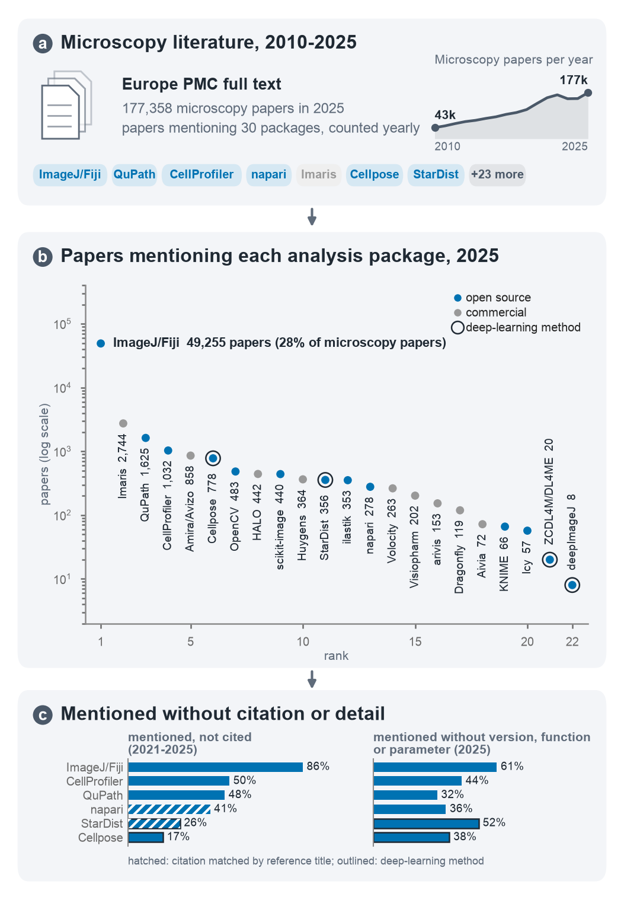

In [6]:
OUTPUT_STEM = 'Figure1__overview'
fig = figure.build_figure()
with TemporaryDirectory(prefix='figure1-notebook-') as notebook_dir, TemporaryDirectory(prefix='figure1-module-') as module_dir:
    fs.save(fig, OUTPUT_STEM, out_dir=notebook_dir)
    figure.main(out_dir=module_dir)
    notebook_png = Path(notebook_dir) / f'{OUTPUT_STEM}.png'
    module_png = Path(module_dir) / f'{OUTPUT_STEM}.png'
    notebook_image = mpimg.imread(notebook_png)
    module_image = mpimg.imread(module_png)
    assert notebook_image.shape == module_image.shape, (notebook_image.shape, module_image.shape)
    np.testing.assert_array_equal(notebook_image, module_image)
    print(f'PNG shape: {notebook_image.shape}; mean absolute pixel difference: {np.abs(notebook_image - module_image).mean():.6f}')
    from io import BytesIO
    from PIL import Image as PILImage
    preview = PILImage.open(notebook_png)
    preview.thumbnail((900, 900))
    preview_bytes = BytesIO()
    preview.save(preview_bytes, format='PNG')
    display(Image(data=preview_bytes.getvalue(), width=min(640, preview.width)))
plt.close('all')